# Módulo B: Series de tiempo (demanda diaria)

> ¿Cuántas órdenes recibirá Olist cada día durante las próximas 4 semanas?

- **Serie:** órdenes por día según `order_purchase_timestamp`, construida en SQL incluyendo días sin órdenes.
- **Partición:** prueba = últimas 8 semanas del período útil (Módulo 0); validación walk-forward
  (origen móvil, horizonte 28 días) sobre los datos anteriores.

**Responsable:** _(nombre)_

In [1]:
# Configuración común: imports, conexión solo lectura y estilo de gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from olist import conectar, consulta, RANDOM_STATE
from olist import config
from olist.graficos import estilo, guardar

estilo()
np.random.seed(RANDOM_STATE)
con = conectar()  # read_only=True: la base cruda no se modifica

from olist import series as ts
import joblib
from statsmodels.tsa.statespace.sarimax import SARIMAX

## 1. Construcción de la serie

594 días, de 2017-01-05 a 2018-08-21; días en cero: 0
Ajuste/validación: 2017-01-05 a 2018-06-26; prueba reservada: 2018-06-27 a 2018-08-21


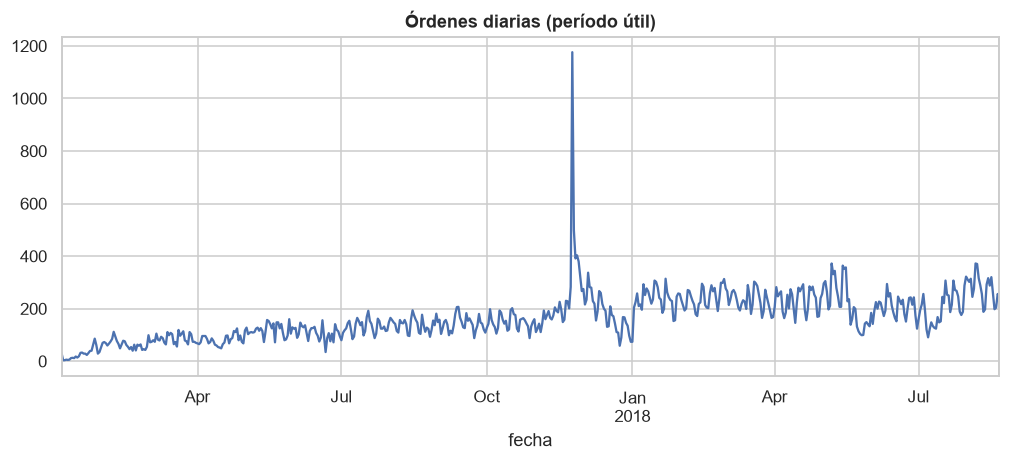

In [2]:
df = consulta(con, "B_series/serie_diaria.sql", [config.FECHA_INICIO_UTIL, config.FECHA_FIN_UTIL])
y = df.set_index(pd.DatetimeIndex(df["fecha"]).rename("fecha"))["ordenes"].astype(float).asfreq("D")
y_trval, y_prueba = ts.separar_prueba(y)
print(f"{len(y)} días, de {y.index.min().date()} a {y.index.max().date()}; días en cero: {(y == 0).sum()}")
print(f"Ajuste/validación: {y_trval.index.min().date()} a {y_trval.index.max().date()}; prueba reservada: {y_prueba.index.min().date()} a {y_prueba.index.max().date()}")
y.plot(title="Órdenes diarias (período útil)");

## 2. Análisis de la serie

Tendencia, estacionalidad semanal, ACF/PACF, estacionariedad (ADF/KPSS) y descomposición.
Identificar y tratar atípicos (Black Friday 2017, festivos, paros) y justificar si se modelan, marcan o excluyen.

,agrupacion,periodo,dias_observados,media_ordenes,mediana_ordenes,total_ordenes
0,dia_semana,0,77,134.3,125,10344.0
1,dia_semana,1,77,181.4,161,13971.0
2,dia_semana,2,77,178.7,168,13759.0
3,dia_semana,3,76,173.8,157,13212.0
4,dia_semana,4,77,163.4,144,12583.0
5,dia_semana,5,77,159.0,141,12246.0
6,dia_semana,6,77,122.3,109,9417.0
7,mes,2017-01,27,29.6,29,800.0
8,mes,2017-02,28,63.6,63,1780.0
9,mes,2017-03,31,86.5,80,2682.0


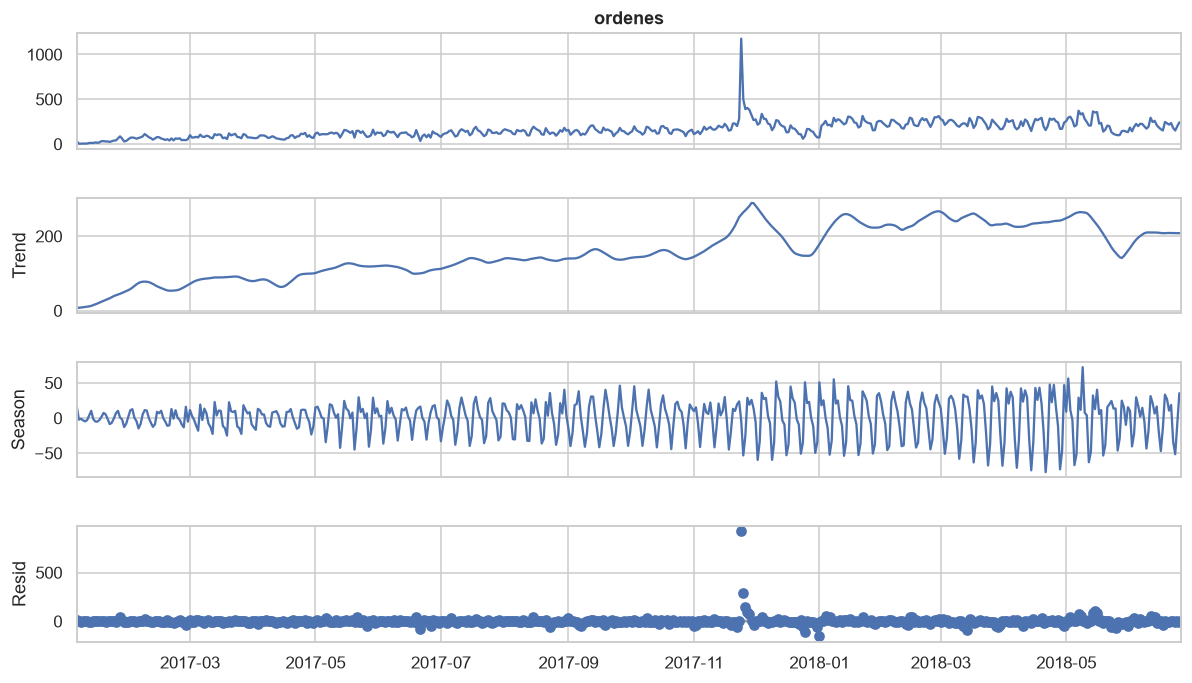

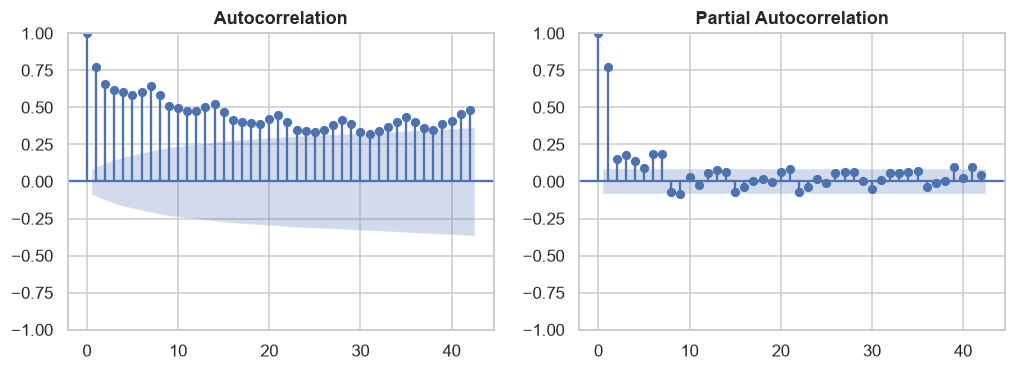

ADF  p-valor (H0: raíz unitaria): 0.0172
KPSS p-valor (H0: estacionaria en nivel): 0.01
ACF por rezago: {1: np.float64(0.771), 7: np.float64(0.641), 14: np.float64(0.522), 28: np.float64(0.415)}
PACF por rezago: {1: np.float64(0.773), 7: np.float64(0.191), 14: np.float64(0.067), 28: np.float64(0.072)}


C:\Users\Usuario\AppData\Local\Temp\ipykernel_3756\3495927021.py:25: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_p = kpss(y_trval, regression="c", nlags="auto", result_object=False)[1]


,count,mean,median,min,max
evento,,,,,
black_friday_2017,15,344.0,275.0,149,1176
paro_camioneros_2018,12,141.9,136.5,99,206
recuperacion_post_paro,7,201.0,200.0,142,227
referencia_black_friday,14,173.1,174.5,111,226
referencia_pre_paro,20,267.7,260.5,139,372


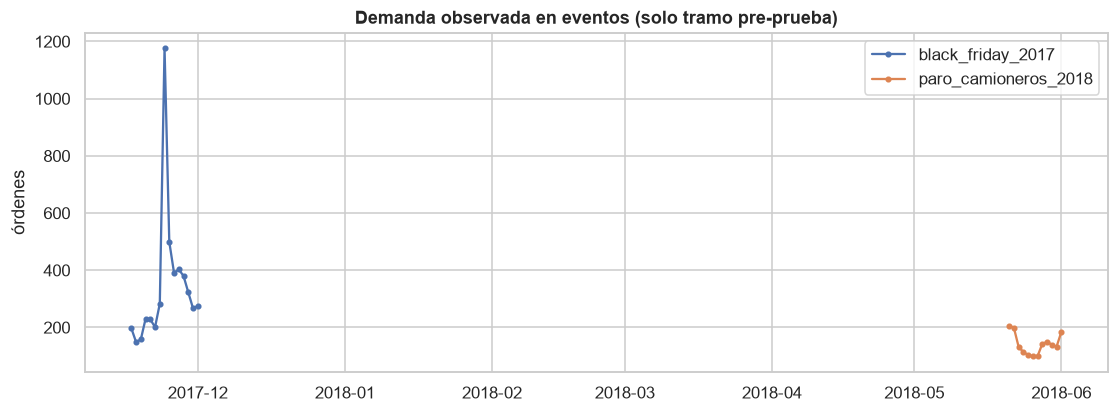

In [3]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

# El análisis de selección usa solo el tramo anterior a la prueba.
calendario_resumen = consulta(
    con, "B_series/analisis_calendario.sql",
    [y_trval.index.min().date().isoformat(), (y_trval.index.max() + pd.Timedelta(days=1)).date().isoformat()],
)
display(calendario_resumen)

stl = STL(y_trval, period=config.ESTACIONALIDAD, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7)
guardar(fig, "stl", "B_series")
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(y_trval, lags=42, ax=axes[0]); plot_pacf(y_trval, lags=42, ax=axes[1])
guardar(fig, "acf_pacf", "B_series")
display(fig)
plt.close(fig)

adf_p = adfuller(y_trval, result_object=False)[1]
kpss_p = kpss(y_trval, regression="c", nlags="auto", result_object=False)[1]
print("ADF  p-valor (H0: raíz unitaria):", round(adf_p, 4))
print("KPSS p-valor (H0: estacionaria en nivel):", round(kpss_p, 4))
lags_interes = [1, 7, 14, 28]
print("ACF por rezago:", dict(zip(lags_interes, acf(y_trval, nlags=28, fft=True)[lags_interes].round(3))))
print("PACF por rezago:", dict(zip(lags_interes, pacf(y_trval, nlags=28)[lags_interes].round(3))))

eventos = consulta(
    con,
    "B_series/eventos_especiales.sql",
    [y_trval.index.min().date().isoformat(), (y_trval.index.max() + pd.Timedelta(days=1)).date().isoformat(),
     "2017-11-17", "2017-12-01", "2017-11-03", "2017-11-16",
     "2018-05-21", "2018-06-01", "2018-05-01", "2018-05-20", "2018-06-02", "2018-06-08"],
)
resumen_eventos = eventos.groupby("evento")["ordenes"].agg(["count", "mean", "median", "min", "max"]).round(1)
display(resumen_eventos)
fig, ax = plt.subplots(figsize=(12, 4))
for evento in ["black_friday_2017", "paro_camioneros_2018"]:
    datos = eventos[eventos["evento"] == evento]
    ax.plot(datos["fecha"], datos["ordenes"], marker="o", ms=3, label=evento)
ax.set(title="Demanda observada en eventos (solo tramo pre-prueba)", ylabel="órdenes")
ax.legend()
guardar(fig, "eventos_especiales", "B_series")
display(fig)
plt.close(fig)

La tendencia mensual aumenta desde 800 órdenes en enero de 2017 hasta 7.544 en noviembre; enero y marzo de 2018 superan 7.200. La media por día de semana muestra oscilación semanal: domingo 134,3 y sábado 122,3 frente a lunes 181,4 y martes 178,7. La ACF en el rezago 7 es 0,641 (rezago 1: 0,771), coherente con persistencia semanal. En el tramo pre-prueba, ADF da p=0,0172 y rechaza raíz unitaria al 5 %, mientras KPSS da p≤0,01 y rechaza estacionariedad en nivel; como sus hipótesis nulas difieren, el resultado es mixto y puede reflejar tendencia o cambios estructurales. Por ello se conserva el ciclo semanal y se comparan pronósticos fuera de muestra, sin imponer estacionariedad en nivel. STL muestra tendencia, componente semanal y residuo.

**Tratamiento acordado:** conservar todas las observaciones. Modelar Black Friday y festivos mediante variables calendario conocidas de antemano (`semana_black_friday`, `festivo` y calendario); no excluir picos de demanda. El 24-nov-2017 registra 1.176 órdenes, frente a una media de 173,1 y máximo de 226 en los 14 días previos. El paro de camioneros (21-may a 1-jun-2018) baja a 141,9 órdenes/día frente a 267,7 del 1 al 20 de mayo, y la media del 2 al 8 de junio es 201,0. Se conservan y marcan para interpretar errores, pero no se usa un indicador de paro futuro no conocido al emitir el pronóstico; es un shock no recurrente.

## 3. Partición: prueba y walk-forward

In [4]:
n_pliegues = 8
pliegues = list(
    ts.walk_forward(y_trval, n_pliegues=n_pliegues, horizonte=config.HORIZONTE,
                    paso=config.HORIZONTE)
)
pliegues_seleccion = pliegues[:-2]
pliegues_calibracion = pliegues[-2:]
print("Entrenamiento+validación:", y_trval.index.min().date(), "→", y_trval.index.max().date())
print("Prueba (no tocar hasta el final):", y_prueba.index.min().date(), "→", y_prueba.index.max().date())
print(f"{len(pliegues_seleccion)} pliegues no solapados para selección; {len(pliegues_calibracion)} reservados para calibrar intervalos.")
pd.DataFrame([{"pliegue": p.numero, "origen": p.origen.date(), "n_entrenamiento": len(p.entrenamiento),
               "validacion": f"{p.validacion.index[0].date()} → {p.validacion.index[-1].date()}"} for p in pliegues])

Entrenamiento+validación: 2017-01-05 → 2018-06-26
Prueba (no tocar hasta el final): 2018-06-27 → 2018-08-21
6 pliegues no solapados para selección; 2 reservados para calibrar intervalos.


,pliegue,origen,n_entrenamiento,validacion
0,0,2017-11-14,314,2017-11-15 → 2017-12-12
1,1,2017-12-12,342,2017-12-13 → 2018-01-09
2,2,2018-01-09,370,2018-01-10 → 2018-02-06
3,3,2018-02-06,398,2018-02-07 → 2018-03-06
4,4,2018-03-06,426,2018-03-07 → 2018-04-03
5,5,2018-04-03,454,2018-04-04 → 2018-05-01
6,6,2018-05-01,482,2018-05-02 → 2018-05-29
7,7,2018-05-29,510,2018-05-30 → 2018-06-26


## 4. Baselines (ingenuo e ingenuo estacional)

In [5]:
resultados_cv = []
for p in pliegues:
    for nombre, funcion in [("ingenuo", ts.pronostico_ingenuo),
                            ("ingenuo_estacional", ts.pronostico_ingenuo_estacional)]:
        pred = funcion(p.entrenamiento, config.HORIZONTE)
        fila = ts.a_formato_largo(nombre, p.origen, p.validacion, pred)
        fila["pliegue"] = p.numero
        resultados_cv.append(fila)
resultados_cv = pd.concat(resultados_cv, ignore_index=True)
def resumir_pliegues(datos):
    por_pliegue = datos.groupby(["modelo", "pliegue"]).apply(
        lambda grupo: pd.Series(ts.metricas(grupo["y"], grupo["yhat"])),
        include_groups=False,
    )
    return por_pliegue.groupby("modelo").agg(["mean", "std"]).round(2)

display(resumir_pliegues(resultados_cv[resultados_cv["pliegue"] < len(pliegues_seleccion)]))

MAE          RMSE         sMAPE       
                     mean    std   mean    std   mean    std
modelo                                                      
ingenuo             60.67  33.98  86.07  67.66  25.24  14.23
ingenuo_estacional  52.17  35.72  76.56  73.60  21.81  13.25

## 5. Modelo estadístico: SARIMA estacional

**Selección del orden.** Se comparan 15 combinaciones de SARIMA(p,1,q)(P,D,Q)[7] por AIC, ajustadas
solo con el entrenamiento del primer pliegue (hasta el 2017-11-14), para que la elección no vea ningún
dato de validación ni de prueba. Como el AIC no es estrictamente comparable entre modelos con distinta
diferenciación estacional (D), los tres mejores por AIC y el orden inicial (1,1,1)(1,0,1)[7] se
comparan además por MAE en los seis pliegues de selección. Se elige el de menor MAE.

Con el orden elegido se ajusta el modelo en cada origen walk-forward. Los intervalos del 90 % salen del
modelo de espacio de estados y se truncan abajo en cero, porque una demanda negativa no es interpretable.

In [6]:
import itertools
import warnings

def ajustar_sarima(serie, orden, estacional):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(
            serie.astype(float), order=orden, seasonal_order=(*estacional, config.ESTACIONALIDAD),
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False, maxiter=150)

# 1) AIC con el entrenamiento del primer pliegue (no ve validación ni prueba)
y_aic = pliegues[0].entrenamiento
grilla_aic = []
for orden, estacional in itertools.product(
    [(0, 1, 1), (1, 1, 1), (2, 1, 1), (1, 1, 2), (2, 1, 2)],
    [(1, 0, 1), (0, 1, 1), (1, 1, 1)],
):
    grilla_aic.append({"orden": orden, "estacional": estacional,
                       "AIC": ajustar_sarima(y_aic, orden, estacional).aic})
grilla_aic = pd.DataFrame(grilla_aic).sort_values("AIC").reset_index(drop=True)
display(grilla_aic.round(1))

# 2) Los 3 mejores por AIC + el orden inicial, comparados por MAE en los pliegues de selección
candidatos_sarima = grilla_aic.head(3)[["orden", "estacional"]].to_records(index=False).tolist()
if ((1, 1, 1), (1, 0, 1)) not in candidatos_sarima:
    candidatos_sarima.append(((1, 1, 1), (1, 0, 1)))
comparacion_sarima = []
for orden, estacional in candidatos_sarima:
    maes = [
        ts.metricas(p.validacion,
                    ajustar_sarima(p.entrenamiento, orden, estacional)
                    .get_forecast(config.HORIZONTE).predicted_mean.clip(lower=0))["MAE"]
        for p in pliegues_seleccion
    ]
    comparacion_sarima.append({"orden": orden, "estacional": estacional,
                               "MAE_media_folds": np.mean(maes), "MAE_std_folds": np.std(maes, ddof=1)})
comparacion_sarima = pd.DataFrame(comparacion_sarima).sort_values("MAE_media_folds")
display(comparacion_sarima.round(2))
orden_sarima, orden_estacional = comparacion_sarima.iloc[0][["orden", "estacional"]]
print(f"Orden elegido: SARIMA{orden_sarima}{orden_estacional}[{config.ESTACIONALIDAD}]")

,orden,estacional,AIC
0,"(2, 1, 2)","(0, 1, 1)",2587.0
1,"(1, 1, 2)","(0, 1, 1)",2591.8
2,"(2, 1, 2)","(1, 1, 1)",2592.5
3,"(1, 1, 2)","(1, 1, 1)",2593.6
4,"(1, 1, 1)","(0, 1, 1)",2597.7
5,"(1, 1, 1)","(1, 1, 1)",2599.6
6,"(2, 1, 1)","(0, 1, 1)",2599.7
7,"(0, 1, 1)","(0, 1, 1)",2600.7
8,"(0, 1, 1)","(1, 1, 1)",2602.2
9,"(2, 1, 1)","(1, 1, 1)",2604.4


,orden,estacional,MAE_media_folds,MAE_std_folds
0,"(2, 1, 2)","(0, 1, 1)",57.86,43.56
3,"(1, 1, 1)","(1, 0, 1)",58.13,35.64
1,"(1, 1, 2)","(0, 1, 1)",58.14,43.49
2,"(2, 1, 2)","(1, 1, 1)",60.11,46.83


Orden elegido: SARIMA(2, 1, 2)(0, 1, 1)[7]


In [7]:
sarima_resultados = []
sarima_intervalos = []
for p in pliegues:
    modelo_sarima = ajustar_sarima(p.entrenamiento, orden_sarima, orden_estacional)
    pronostico = modelo_sarima.get_forecast(steps=config.HORIZONTE)
    pred = pronostico.predicted_mean.clip(lower=0)
    intervalo = pronostico.conf_int(alpha=0.10)
    fila = ts.a_formato_largo("sarima", p.origen, p.validacion, pred)
    fila["pliegue"] = p.numero
    sarima_resultados.append(fila)
    sarima_intervalos.append(pd.DataFrame({
        "modelo": "sarima", "pliegue": p.numero, "fecha": p.validacion.index,
        "y": p.validacion.to_numpy(),
        "inferior": np.maximum(intervalo.iloc[:, 0].to_numpy(), 0),
        "superior": intervalo.iloc[:, 1].to_numpy(),
    }))
sarima_resultados = pd.concat(sarima_resultados, ignore_index=True)
sarima_intervalos = pd.concat(sarima_intervalos, ignore_index=True)
resultados_cv = pd.concat([resultados_cv, sarima_resultados], ignore_index=True)
display(resumir_pliegues(sarima_resultados[sarima_resultados["pliegue"] < len(pliegues_seleccion)]))

MAE          RMSE         sMAPE       
         mean    std   mean    std   mean    std
modelo                                          
sarima  57.86  43.56  81.58  77.87  24.01  17.87

## 6. Modelo de ML: LightGBM con rezagos, medias móviles y calendario

Se comparan dos estrategias con las mismas familias de variables y ajuste walk-forward:
- **Recursiva:** se entrena un modelo de un paso y cada predicción se realimenta como rezago.
- **Directa agrupada:** un modelo predice los horizontes 1–28 usando rezagos del origen, calendario de la fecha objetivo y el paso adelante; no reutiliza objetivos futuros.

La búsqueda usa tres configuraciones prefijadas y solo los primeros seis pliegues; los dos pliegues más recientes quedan reservados para calibración de intervalos. La prueba no participa en ajuste ni selección.

In [8]:
candidatos = {
    "compacto": {"n_estimators": 250, "learning_rate": 0.03, "num_leaves": 7, "min_child_samples": 20},
    "base": {"n_estimators": 400, "learning_rate": 0.03, "num_leaves": 15, "min_child_samples": 10},
    "mayor_capacidad": {"n_estimators": 600, "learning_rate": 0.02, "num_leaves": 31, "min_child_samples": 20},
}
resultados_grid = []
for estrategia in ["recursivo", "directo"]:
    for nombre_parametros, parametros in candidatos.items():
        for p in pliegues_seleccion:
            if estrategia == "recursivo":
                modelo_lgbm = ts.entrenar_lightgbm(
                    p.entrenamiento, random_state=RANDOM_STATE, **parametros
                )
                pred = ts.pronostico_recursivo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
                nombre_modelo = f"lightgbm_recursivo_{nombre_parametros}"
            else:
                modelo_lgbm = ts.entrenar_lightgbm_directo(
                    p.entrenamiento, random_state=RANDOM_STATE, **parametros
                )
                pred = ts.pronostico_directo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
                nombre_modelo = f"lightgbm_directo_{nombre_parametros}"
            fila = ts.a_formato_largo(nombre_modelo, p.origen, p.validacion, pred.clip(lower=0))
            fila["pliegue"] = p.numero
            resultados_grid.append(fila)
resultados_grid = pd.concat(resultados_grid, ignore_index=True)

resumen_grid = []
for nombre, datos in resultados_grid.groupby("modelo"):
    por_pliegue = datos.groupby("pliegue").apply(
        lambda grupo: pd.Series(ts.metricas(grupo["y"], grupo["yhat"])),
        include_groups=False,
    )
    resumen_grid.append({
        "modelo": nombre,
        "MAE_media_folds": por_pliegue["MAE"].mean(),
        "MAE_std_folds": por_pliegue["MAE"].std(),
        "RMSE_media_folds": por_pliegue["RMSE"].mean(),
        "sMAPE_media_folds": por_pliegue["sMAPE"].mean(),
    })
resumen_grid = pd.DataFrame(resumen_grid).sort_values("MAE_media_folds")
display(resumen_grid.round(2))
mejores_estrategia = {
    estrategia: resumen_grid[resumen_grid["modelo"].str.startswith(f"lightgbm_{estrategia}_")].iloc[0]["modelo"]
    for estrategia in ["recursivo", "directo"]
}
parametros_elegidos = {
    nombre: candidatos[nombre.removeprefix(f"lightgbm_{estrategia}_")]
    for estrategia, nombre in mejores_estrategia.items()
}
print("Mejor configuración por estrategia:", mejores_estrategia)
print("Parámetros elegidos:", parametros_elegidos)

resultados_lgbm = []
calibracion_lgbm = []
for estrategia, nombre_modelo in mejores_estrategia.items():
    parametros = parametros_elegidos[nombre_modelo]
    for p in pliegues:
        if estrategia == "recursivo":
            modelo_lgbm = ts.entrenar_lightgbm(
                p.entrenamiento, random_state=RANDOM_STATE, **parametros
            )
            pred = ts.pronostico_recursivo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
        else:
            modelo_lgbm = ts.entrenar_lightgbm_directo(
                p.entrenamiento, random_state=RANDOM_STATE, **parametros
            )
            pred = ts.pronostico_directo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
        fila = ts.a_formato_largo(f"lightgbm_{estrategia}", p.origen, p.validacion, pred.clip(lower=0))
        fila["pliegue"] = p.numero
        resultados_lgbm.append(fila)
        if p.numero >= len(pliegues_seleccion):
            calibracion_lgbm.append(fila)
resultados_lgbm = pd.concat(resultados_lgbm, ignore_index=True)
calibracion_lgbm = pd.concat(calibracion_lgbm, ignore_index=True)
resultados_cv = pd.concat([resultados_cv, resultados_lgbm], ignore_index=True)
display(resumir_pliegues(resultados_lgbm[resultados_lgbm["pliegue"] < len(pliegues_seleccion)]))

,modelo,MAE_media_folds,MAE_std_folds,RMSE_media_folds,sMAPE_media_folds
1,lightgbm_directo_compacto,63.26,53.83,91.95,26.97
2,lightgbm_directo_mayor_capacidad,64.17,56.67,95.52,26.76
0,lightgbm_directo_base,64.38,56.52,95.80,26.74
4,lightgbm_recursivo_compacto,74.28,44.12,100.36,30.80
5,lightgbm_recursivo_mayor_capacidad,74.51,45.96,101.93,30.37
3,lightgbm_recursivo_base,99.07,54.23,128.95,36.86


Mejor configuración por estrategia: {'recursivo': 'lightgbm_recursivo_compacto', 'directo': 'lightgbm_directo_compacto'}
Parámetros elegidos: {'lightgbm_recursivo_compacto': {'n_estimators': 250, 'learning_rate': 0.03, 'num_leaves': 7, 'min_child_samples': 20}, 'lightgbm_directo_compacto': {'n_estimators': 250, 'learning_rate': 0.03, 'num_leaves': 7, 'min_child_samples': 20}}


MAE           RMSE         sMAPE       
                     mean    std    mean    std   mean    std
modelo                                                       
lightgbm_directo    63.26  53.83   91.95  90.23  26.97  24.28
lightgbm_recursivo  74.28  44.12  100.36  76.03  30.80  17.84

## 7. Métricas por horizonte

MAE           RMSE         sMAPE       
                     mean    std    mean    std   mean    std
modelo                                                       
ingenuo             60.67  33.98   86.07  67.66  25.24  14.23
ingenuo_estacional  52.17  35.72   76.56  73.60  21.81  13.25
lightgbm_directo    63.26  53.83   91.95  90.23  26.97  24.28
lightgbm_recursivo  74.28  44.12  100.36  76.03  30.80  17.84
sarima              57.86  43.56   81.58  77.87  24.01  17.87

Modelo elegido por MAE medio en los seis pliegues de selección: ingenuo_estacional


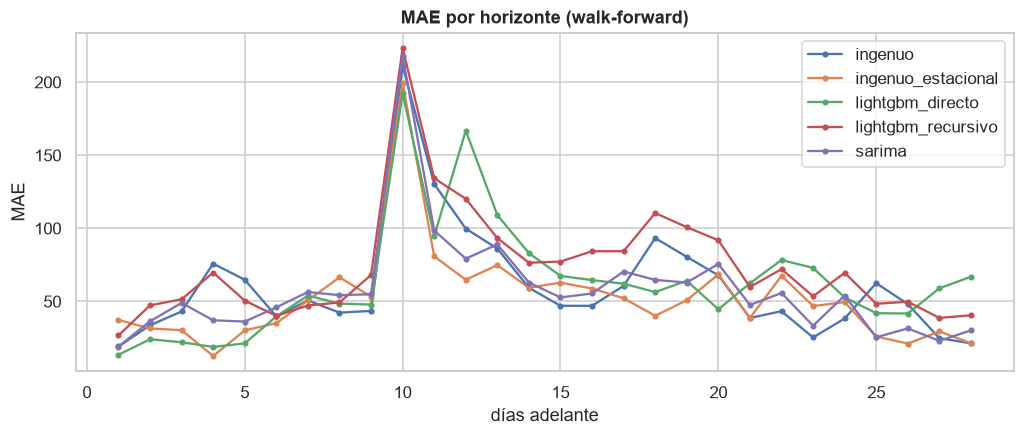

,modelo,h,MAE,RMSE,sMAPE
0,ingenuo,1,19.166667,22.616366,7.741352
1,ingenuo,2,33.666667,36.801268,14.180370
2,ingenuo,3,43.166667,50.476067,18.766531
3,ingenuo,4,75.833333,82.130993,36.508058
4,ingenuo,5,64.833333,74.658110,30.843016
...,...,...,...,...,...
135,sarima,24,54.035359,71.507256,23.241634
136,sarima,25,25.447261,34.634689,12.900044
137,sarima,26,31.541599,36.893967,15.041666
138,sarima,27,23.014869,31.602210,9.270930


In [9]:
modelos_seleccion = ["ingenuo", "ingenuo_estacional", "sarima", "lightgbm_recursivo", "lightgbm_directo"]
datos_seleccion = resultados_cv[
    resultados_cv["modelo"].isin(modelos_seleccion)
    & (resultados_cv["pliegue"] < len(pliegues_seleccion))
].copy()
resumen_seleccion = resumir_pliegues(datos_seleccion)
display(resumen_seleccion)
ganador_cv = resumen_seleccion[("MAE", "mean")].idxmin()
print("Modelo elegido por MAE medio en los seis pliegues de selección:", ganador_cv)
por_h = ts.metricas_por_horizonte(datos_seleccion)
fig, ax = plt.subplots()
for nombre, g in por_h.groupby("modelo"):
    ax.plot(g["h"], g["MAE"], marker="o", ms=3, label=nombre)
ax.set(title="MAE por horizonte (walk-forward)", xlabel="días adelante", ylabel="MAE")
ax.legend()
guardar(fig, "mae_por_horizonte", "B_series")
display(fig)
plt.close(fig)
display(por_h)

## 8. Incertidumbre: intervalos de predicción y cobertura empírica

Para SARIMA se conservan los intervalos del 90 % del modelo de espacio de estados. Para LightGBM se calibra un intervalo conformal simétrico con el percentil empírico 90 de errores absolutos de los dos pliegues recientes reservados. La cobertura y el ancho se reportan en la prueba; la deriva temporal puede degradar la cobertura.

In [10]:
cuantiles_error = {}
for estrategia in ["recursivo", "directo"]:
    errores = calibracion_lgbm.loc[
        calibracion_lgbm["modelo"] == f"lightgbm_{estrategia}", "y"
    ].to_numpy() - calibracion_lgbm.loc[
        calibracion_lgbm["modelo"] == f"lightgbm_{estrategia}", "yhat"
    ].to_numpy()
    cuantiles_error[estrategia] = np.quantile(np.abs(errores), 0.90, method="higher")
print("Cuantiles conformales absolutos, calibración reservada:", cuantiles_error)
display(sarima_intervalos[sarima_intervalos["pliegue"] >= len(pliegues_seleccion)].groupby("pliegue").apply(
    lambda grupo: pd.Series({
        "cobertura_SARIMA": ((grupo["y"] >= grupo["inferior"]) & (grupo["y"] <= grupo["superior"])).mean(),
        "ancho_medio": (grupo["superior"] - grupo["inferior"]).mean(),
    }), include_groups=False
).round(3))

Cuantiles conformales absolutos, calibración reservada: {'recursivo': np.float64(116.27138838869519), 'directo': np.float64(106.85753305069869)}


,cobertura_SARIMA,ancho_medio
pliegue,,
6,0.75,203.382
7,1.00,247.983


## 9. Evaluación final en prueba (una sola vez)

La selección queda congelada con los seis pliegues walk-forward anteriores. La prueba (56 días) se
evalúa **una sola vez** y con el mismo horizonte del problema: **dos ventanas de 28 días**.

- Ventana 1: origen el último día antes de la prueba; se pronostican los días 1–28.
- Ventana 2: origen 28 días después; los modelos se reajustan con los datos reales observados hasta ese
  origen, **con los mismos hiperparámetros** (no se vuelve a seleccionar nada), y se pronostican los días 29–56.

Así cada horizonte h = 1…28 tiene dos observaciones en prueba, igual que en la operación real, donde se
pronostica cada 4 semanas con los datos disponibles. Los intervalos son el 90 % de SARIMA y el conformal
de LightGBM calibrado en los dos pliegues reservados.

,MAE,RMSE,sMAPE
modelo,,,
lightgbm_recursivo,37.47,48.66,17.86
ingenuo_estacional,38.93,48.93,18.00
sarima,47.43,60.22,21.68
lightgbm_directo,50.57,61.61,22.94
ingenuo,54.89,67.07,24.95


Selección previa a la prueba (walk-forward): ingenuo_estacional
MAE por ventana:


ventana,1,2
modelo,,
ingenuo,64.64,45.14
ingenuo_estacional,44.36,33.50
lightgbm_directo,43.71,57.44
lightgbm_recursivo,49.53,25.40
sarima,51.63,43.22


Cobertura empírica de los intervalos del 90 % en los 56 días de prueba:


,cobertura_90,ancho_medio
modelo,,
lightgbm_directo,0.946,213.715
lightgbm_recursivo,1.000,232.543
sarima,0.875,210.745


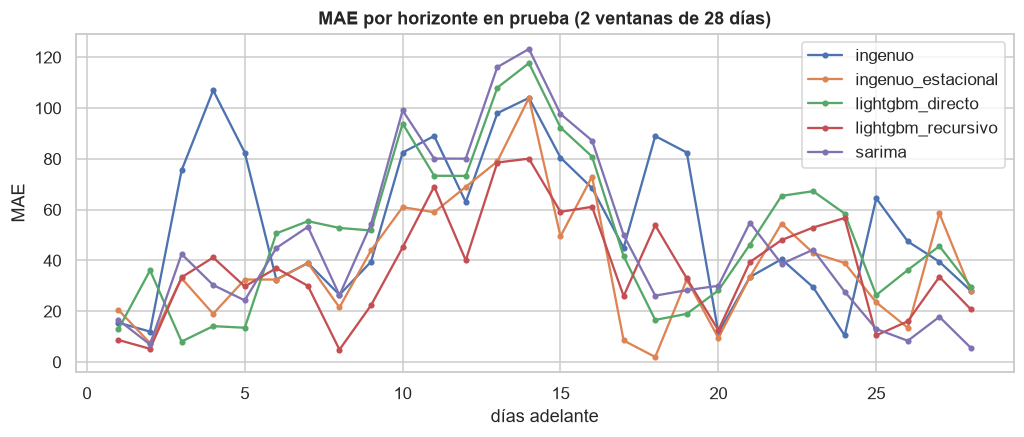

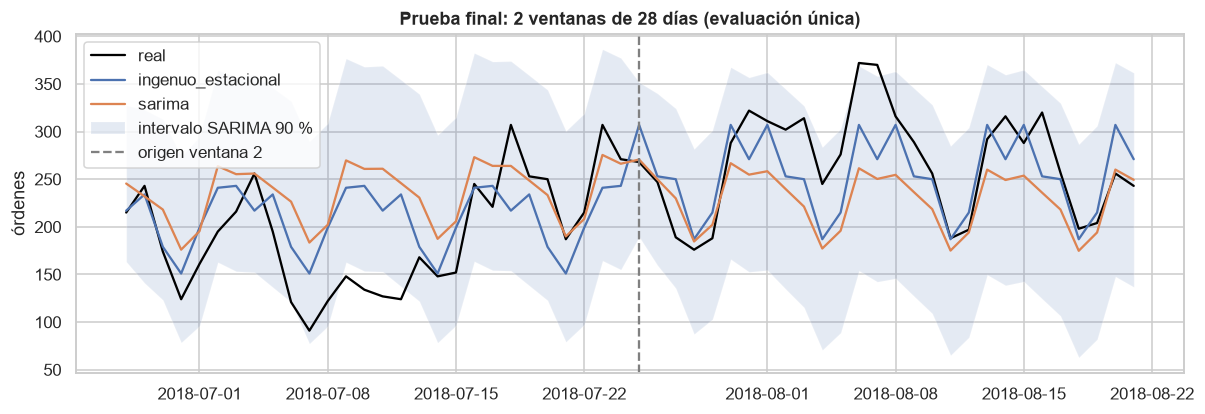

Artefacto para D: models\lightgbm_series.joblib | estrategia: directo


In [11]:
ventanas_prueba = [y_prueba.iloc[:config.HORIZONTE], y_prueba.iloc[config.HORIZONTE:2 * config.HORIZONTE]]
filas_prueba, intervalos_prueba = [], []
modelos_ventana1 = {}

for numero, ventana in enumerate(ventanas_prueba, start=1):
    historia = y.loc[: ventana.index[0] - pd.Timedelta(days=1)]  # solo datos observados al origen
    origen = historia.index[-1]
    predicciones = {
        "ingenuo": ts.pronostico_ingenuo(historia, len(ventana)),
        "ingenuo_estacional": ts.pronostico_ingenuo_estacional(historia, len(ventana)),
    }
    sarima_final = ajustar_sarima(historia, orden_sarima, orden_estacional)
    pron_sarima = sarima_final.get_forecast(steps=len(ventana))
    predicciones["sarima"] = pron_sarima.predicted_mean.clip(lower=0)
    ic = pron_sarima.conf_int(alpha=0.10)
    intervalos_prueba.append(pd.DataFrame({
        "modelo": "sarima", "ventana": numero, "fecha": ventana.index, "y": ventana.to_numpy(),
        "inferior": np.maximum(ic.iloc[:, 0].to_numpy(), 0), "superior": ic.iloc[:, 1].to_numpy(),
    }))
    for estrategia in ["recursivo", "directo"]:
        parametros = parametros_elegidos[mejores_estrategia[estrategia]]
        if estrategia == "recursivo":
            modelo_final = ts.entrenar_lightgbm(historia, random_state=RANDOM_STATE, **parametros)
            pred = ts.pronostico_recursivo(modelo_final, historia, len(ventana))
        else:
            modelo_final = ts.entrenar_lightgbm_directo(historia, random_state=RANDOM_STATE, **parametros)
            pred = ts.pronostico_directo(modelo_final, historia, len(ventana))
        pred = pred.clip(lower=0)
        predicciones[f"lightgbm_{estrategia}"] = pred
        q = cuantiles_error[estrategia]
        intervalos_prueba.append(pd.DataFrame({
            "modelo": f"lightgbm_{estrategia}", "ventana": numero, "fecha": ventana.index,
            "y": ventana.to_numpy(), "inferior": np.maximum(pred.to_numpy() - q, 0),
            "superior": pred.to_numpy() + q,
        }))
        if numero == 1:
            modelos_ventana1[estrategia] = modelo_final
    for nombre, pred in predicciones.items():
        fila = ts.a_formato_largo(nombre, origen, ventana, pred)
        fila["ventana"] = numero
        filas_prueba.append(fila)

resultados_prueba = pd.concat(filas_prueba, ignore_index=True)
intervalos_prueba = pd.concat(intervalos_prueba, ignore_index=True)

tabla_prueba = resultados_prueba.groupby("modelo")[["y", "yhat"]].apply(
    lambda g: pd.Series(ts.metricas(g["y"], g["yhat"]))
).sort_values("MAE")
display(tabla_prueba.round(2))
print("Selección previa a la prueba (walk-forward):", ganador_cv)
print("MAE por ventana:")
display(resultados_prueba.groupby(["modelo", "ventana"])[["y", "yhat"]].apply(
    lambda g: ts.metricas(g["y"], g["yhat"])["MAE"]).unstack().round(2))

cobertura_prueba = intervalos_prueba.groupby("modelo").apply(lambda g: pd.Series({
    "cobertura_90": ts.cobertura_empirica(g["y"], g["inferior"], g["superior"]),
    "ancho_medio": (g["superior"] - g["inferior"]).mean(),
}), include_groups=False)
print("Cobertura empírica de los intervalos del 90 % en los 56 días de prueba:")
display(cobertura_prueba.round(3))

# Error por horizonte en prueba (2 observaciones por h)
por_h_prueba = ts.metricas_por_horizonte(resultados_prueba)
fig, ax = plt.subplots()
for nombre, g in por_h_prueba.groupby("modelo"):
    ax.plot(g["h"], g["MAE"], marker="o", ms=3, label=nombre)
ax.set(title="MAE por horizonte en prueba (2 ventanas de 28 días)", xlabel="días adelante", ylabel="MAE")
ax.legend()
guardar(fig, "mae_por_horizonte_prueba", "B_series")
display(fig)
plt.close(fig)

# Gráfico de la prueba: real, modelo elegido en CV, SARIMA e intervalo SARIMA
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(y_prueba.index, y_prueba, color="black", label="real")
for nombre in dict.fromkeys([ganador_cv, "sarima"]):
    datos = resultados_prueba[resultados_prueba["modelo"] == nombre]
    ax.plot(datos["fecha"], datos["yhat"], label=nombre)
ic_sarima = intervalos_prueba[intervalos_prueba["modelo"] == "sarima"]
ax.fill_between(ic_sarima["fecha"], ic_sarima["inferior"], ic_sarima["superior"],
                alpha=0.15, label="intervalo SARIMA 90 %")
ax.axvline(ventanas_prueba[1].index[0], color="grey", ls="--", label="origen ventana 2")
ax.set(title="Prueba final: 2 ventanas de 28 días (evaluación única)", ylabel="órdenes")
ax.legend()
guardar(fig, "prueba_final", "B_series")
display(fig)
plt.close(fig)

# Artefacto para el Módulo D: LightGBM elegido, entrenado solo con datos previos a la prueba
ganador_lgbm = min(
    ["recursivo", "directo"],
    key=lambda estrategia: resumen_seleccion.loc[f"lightgbm_{estrategia}", ("MAE", "mean")],
)
modelo_lgbm_guardado = modelos_ventana1[ganador_lgbm]
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
ruta_modelo = config.MODELS_DIR / "lightgbm_series.joblib"
joblib.dump({
    "modelo": modelo_lgbm_guardado,
    "estrategia": ganador_lgbm,
    "parametros": parametros_elegidos[mejores_estrategia[ganador_lgbm]],
    "features": list(modelo_lgbm_guardado.feature_name_),
    "fecha_corte_entrenamiento": y_trval.index.max().isoformat(),
    "cuantil_conformal_90": float(cuantiles_error[ganador_lgbm]),
}, ruta_modelo)
print("Artefacto para D:", ruta_modelo.relative_to(config.PROJECT_ROOT), "| estrategia:", ganador_lgbm)

## 10. Cómo crece el error con el horizonte

MAE medio por semana de horizonte (días 1–7, 8–14, 15–21 y 22–28), en validación (6 pliegues) y en prueba (2 ventanas).

In [12]:
def por_semana_horizonte(metricas_h):
    """MAE medio por semana de horizonte a partir de la tabla de métricas por h."""
    semana = (metricas_h["h"] - 1) // 7 + 1
    etiqueta = "semana " + semana.astype(str) + " (días " + ((semana - 1) * 7 + 1).astype(str) \
        + "-" + (semana * 7).astype(str) + ")"
    return metricas_h.assign(semana=etiqueta).groupby(["modelo", "semana"])["MAE"].mean().unstack().round(1)

print("Validación walk-forward (6 pliegues de selección):")
display(por_semana_horizonte(por_h))
print("Prueba (2 ventanas de 28 días):")
display(por_semana_horizonte(por_h_prueba))

Validación walk-forward (6 pliegues de selección):


semana,semana 1 (días 1-7),semana 2 (días 8-14),semana 3 (días 15-21),semana 4 (días 22-28)
modelo,,,,
ingenuo,46.7,96.1,62.1,37.7
ingenuo_estacional,32.5,85.6,53.1,37.4
lightgbm_directo,27.7,106.1,60.2,59.1
lightgbm_recursivo,47.6,109.3,87.0,53.2
sarima,40.0,93.8,61.4,36.2


Prueba (2 ventanas de 28 días):


semana,semana 1 (días 1-7),semana 2 (días 8-14),semana 3 (días 15-21),semana 4 (días 22-28)
modelo,,,,
ingenuo,52.0,71.8,58.6,37.1
ingenuo_estacional,26.3,62.5,29.8,37.1
lightgbm_directo,27.3,81.6,46.4,47.0
lightgbm_recursivo,26.5,48.6,40.7,34.1
sarima,31.3,82.8,53.5,22.2


## Conclusiones del MÃ³dulo B

**Serie.** 594 dÃ­as (2017-01-05 a 2018-08-21), sin dÃ­as en cero. Tiene tendencia creciente y una estacionalidad semanal marcada: los sÃ¡bados y domingos tienen menos Ã³rdenes (ACF en el rezago 7 = 0,64). ADF y KPSS dan un resultado mixto, por lo que se modela con diferenciaciÃ³n y se evalÃºa fuera de muestra. Black Friday 2017 (1.176 Ã³rdenes frente a unas 173 diarias) se conserva y se modela con variables de calendario. El paro de camioneros de mayo de 2018 se conserva y se usa para interpretar errores.

**SelecciÃ³n (walk-forward, 6 pliegues de 28 dÃ­as sin solape).**

| Modelo | MAE medio | sMAPE medio |
|---|---|---|
| Ingenuo estacional | **52,2** | 21,8 % |
| SARIMA(2,1,2)(0,1,1)[7] | 57,9 | 24,0 % |
| Ingenuo | 60,7 | 25,2 % |
| LightGBM directo | 63,3 | 27,0 % |
| LightGBM recursivo | 74,3 | 30,8 % |

NingÃºn modelo superÃ³ en promedio al ingenuo estacional, que fue el elegido antes de ver la prueba. La variabilidad entre pliegues es alta (desviaciÃ³n de 34 a 54) porque el primer pliegue contiene Black Friday en el horizonte 10: es el pico del grÃ¡fico de MAE por horizonte. El orden de SARIMA se eligiÃ³ por AIC entre 15 combinaciones y se confirmÃ³ por MAE. La diferencia con el orden inicial (58,1) es pequeÃ±a.

**Prueba (2 ventanas de 28 dÃ­as, evaluaciÃ³n Ãºnica).**

| Modelo | MAE | sMAPE |
|---|---|---|
| LightGBM recursivo | **37,5** | 17,9 % |
| Ingenuo estacional | 38,9 | 18,0 % |
| SARIMA | 47,4 | 21,7 % |
| LightGBM directo | 50,6 | 22,9 % |
| Ingenuo | 54,9 | 25,0 % |

El modelo elegido en validaciÃ³n quedÃ³ a solo 1,5 Ã³rdenes de MAE del mejor en prueba, asÃ­ que la selecciÃ³n fue robusta. El LightGBM recursivo, Ãºltimo en validaciÃ³n, fue primero en prueba. Ese cambio de ranking entre periodos indica que las diferencias entre modelos son pequeÃ±as frente a la variabilidad de la demanda. La ventana 1 fue la mÃ¡s difÃ­cil: del 6 al 15 de julio de 2018 la demanda cayÃ³ a 91â€“168 Ã³rdenes diarias (media de la ventana: 192, frente a 267 en la ventana 2) y ningÃºn modelo lo anticipÃ³. Esa caÃ­da coincide con el periodo entre la eliminaciÃ³n de Brasil del Mundial y la final; es una hipÃ³tesis que el dataset no permite confirmar.

**Error segÃºn el horizonte.** En la primera semana todos los buenos modelos rondan un MAE de 26â€“33. En validaciÃ³n, el LightGBM directo es el mejor de la semana 1 (27,7) y se degrada despuÃ©s. El error no crece de forma monÃ³tona: las semanas 2 y 3 son peores que la 4, porque los eventos (Black Friday en validaciÃ³n, la caÃ­da de julio en prueba) dominan el error mÃ¡s que la distancia al origen.

**Incertidumbre.** Cobertura empÃ­rica de los intervalos del 90 % en los 56 dÃ­as de prueba: SARIMA 87,5 % (ancho medio 211 Ã³rdenes), LightGBM directo conformal 94,6 % (214) y LightGBM recursivo conformal 100 % (233). SARIMA estÃ¡ cerca del nivel nominal; el conformal recursivo es conservador. Los anchos equivalen a casi toda la demanda media de la prueba (230 Ã³rdenes diarias), asÃ­ que sirven para fijar un techo de capacidad, no como pronÃ³stico puntual preciso.

**RecomendaciÃ³n.** Usar el ingenuo estacional o SARIMA como pronÃ³stico base de las 4 semanas, y los intervalos para dimensionar la capacidad mÃ¡xima. El LightGBM directo, el mejor LightGBM en validaciÃ³n, es el modelo que se interpreta en el MÃ³dulo D. Trabajo futuro: combinar modelos, agregar variables de eventos conocidos de antemano (campaÃ±as, festivos regionales) y reentrenar cada semana para reducir el efecto de la deriva.

In [13]:
con.close()